In [5]:
pip install matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 1.3 MB/s eta 0:00:002.3 MB/s eta 0:00:01
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.2/137.2 kB 3.5 MB/s eta 0:00:007.4 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 2.2 MB/s eta 0:00:00m eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 383.2/383.2 kB 2.7 MB/s eta 0:00:00 MB/s eta 0:00:01:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 2.3 MB/s eta 0:00:00m eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 2.3 MB/s eta 0:00:00m eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 2.3 MB/s eta 0:00:00m eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 kB 2.1 MB/s eta 0:00:00MB/s eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np

In [2]:
def f(t, x):
    return -x                      # the rule: how fast x changes

def rk4_step(f, t, x, h):
    k1 = f(t, x)                   # slope at start
    k2 = f(t + h/2, x + h/2 * k1)  # slope at middle (using k1)
    k3 = f(t + h/2, x + h/2 * k2)  # slope at middle again (using k2)
    k4 = f(t + h, x + h * k3)      # slope at end
    return x + h/6 * (k1 + 2*k2 + 2*k3 + k4)

for h in [0.1, 0.05, 0.025]:
    t, x = 0.0, 1.0
    while t < 1.0 - 1e-12:
        x = rk4_step(f, t, x, h)
        t += h
    print(h, abs(x - np.exp(-1)))

0.1 3.3324105608301124e-07
0.05 1.9976097331841913e-08
0.025 1.2227420187471694e-09


error at t=3: 4.75068873129203e-11 1.8199841633759206e-10


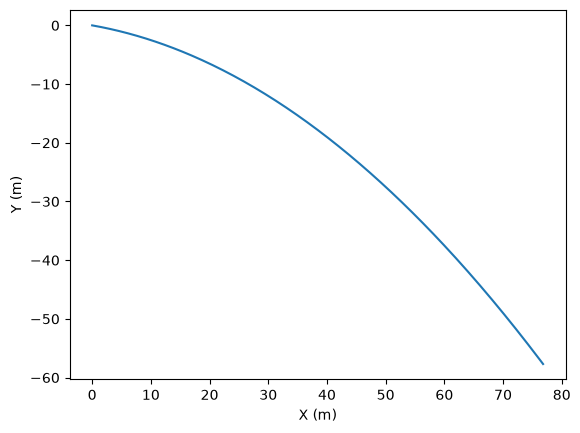

In [6]:
import numpy as np
import matplotlib.pyplot as plt

g = 9.81

def f(t, s):
    X, Y, U, beta, phi, omega = s
    L, D, M = 0.0, 0.0, 0.0        # air switched off (for now)
    m, I = 60.0, 10.0              # placeholder mass and inertia
    return np.array([
        U * np.cos(beta),                      # dX/dt
        U * np.sin(beta),                      # dY/dt
        -g * np.sin(beta) - D / m,             # dU/dt
        (L / m - g * np.cos(beta)) / U,        # dbeta/dt
        omega,                                 # dphi/dt
        M / I,                                 # domega/dt
    ])

def rk4_step(f, t, x, h):
    k1 = f(t, x)
    k2 = f(t + h/2, x + h/2 * k1)
    k3 = f(t + h/2, x + h/2 * k2)
    k4 = f(t + h, x + h * k3)
    return x + h/6 * (k1 + 2*k2 + 2*k3 + k4)

U0, beta0 = 26.0, np.radians(-10)              # rough take-off values
s = np.array([0.0, 0.0, U0, beta0, 0.0, 0.0])
h, t = 0.01, 0.0
path = [s]
while t < 3.0 - 1e-12:
    s = rk4_step(f, t, s, h)
    t += h
    path.append(s)
path = np.array(path)

# exact parabola for comparison
X_exact = U0 * np.cos(beta0) * t
Y_exact = U0 * np.sin(beta0) * t - g * t**2 / 2
print("error at t=3:", abs(path[-1, 0] - X_exact), abs(path[-1, 1] - Y_exact))

plt.plot(path[:, 0], path[:, 1])
plt.xlabel("X (m)"); plt.ylabel("Y (m)"); plt.axis("equal")
plt.show()

In [10]:
H, slope = 3.0, np.radians(35)

def hill(X):
    return -H - np.tan(slope) * X        # hill height at position X

def simulate(h):
    s = np.array([0.0, 0.0, U0, beta0, 0.0, 0.0])
    t = 0.0
    while True:
        s_new = rk4_step(f, t, s, h)
        if s_new[1] <= hill(s_new[0]):   # crossed the hill in this step
            break
        s, t = s_new, t + h              # still above: accept the step

    # touchdown is somewhere between t and t + h
    lo, hi = 0.0, h
    for _ in range(50):
        mid = (lo + hi) / 2
        s_mid = rk4_step(f, t, s, mid)   # a shorter RK4 step from the last point above
        if s_mid[1] > hill(s_mid[0]):
            lo = mid                     # still above: touchdown is later
        else:
            hi = mid                     # below: touchdown is earlier
    return rk4_step(f, t, s, lo)[0]

# exact landing for the no-air case (parabola meets straight line)
B = U0 * np.sin(beta0) + np.tan(slope) * U0 * np.cos(beta0)
t_land = (B + np.sqrt(B**2 + 2 * g * H)) / g
X_exact = U0 * np.cos(beta0) * t_land

for h in [0.1, 0.05, 0.025, 0.0125]:
    X = simulate(h)
    print(h, X, abs(X - X_exact))

0.1 75.34535999778596 4.045936606189571e-06
0.05 75.34535620435702 2.5250766100270994e-07
0.025 75.34535596761732 1.5767966488056118e-08
0.0125 75.34535595283462 9.852669791143853e-10


In [9]:
def simulate(h):
    s = np.array([0.0, 0.0, U0, beta0, 0.0, 0.0])
    t = 0.0
    while True:
        s_new = rk4_step(f, t, s, h)
        if s_new[1] <= hill(s_new[0]):   # crossed the hill in this step
            break
        s, t = s_new, t + h              # still above: accept the step

    # touchdown is somewhere between t and t + h
    lo, hi = 0.0, h
    for _ in range(50):
        mid = (lo + hi) / 2
        s_mid = rk4_step(f, t, s, mid)   # a shorter RK4 step from the last point above
        if s_mid[1] > hill(s_mid[0]):
            lo = mid                     # still above: touchdown is later
        else:
            hi = mid                     # below: touchdown is earlier
    return rk4_step(f, t, s, lo)[0]

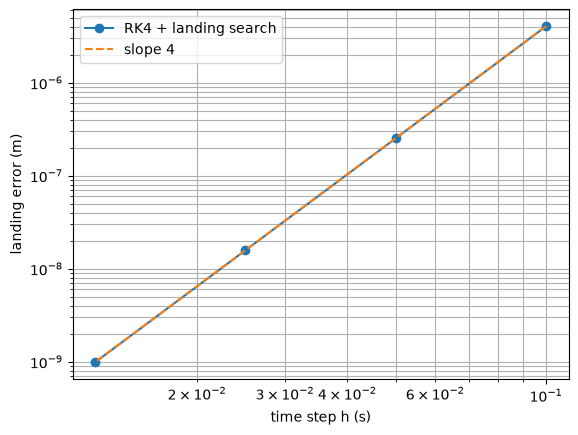

In [11]:
hs = [0.1, 0.05, 0.025, 0.0125]
errs = [abs(simulate(h) - X_exact) for h in hs]

plt.loglog(hs, errs, "o-", label="RK4 + landing search")
plt.loglog(hs, [errs[0] * (h / hs[0])**4 for h in hs], "--", label="slope 4")
plt.xlabel("time step h (s)"); plt.ylabel("landing error (m)")
plt.legend(); plt.grid(True, which="both"); plt.show()